# 01 — Data Exploration
**IDX Exchange Data Science Internship — Predicting California Home Close Prices**

Author: Saanvi Prasad

This notebook covers:
- **Week 1:** confirm I can load the data, and write a short note on what the key columns mean.
- **Week 2:** load the data into pandas, keep only single-family homes, and look at the distributions of `ClosePrice`, `LivingArea`, bedrooms, bathrooms, and lot size.

**Goal of the project:** predict `ClosePrice` (the final sale price of a home) using the home's characteristics.

## Setup

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.2f}".format)


path = r"C:\Users\saanv\Desktop\idxexchange"

---
# Week 1 — Dataset Access & Key Columns


### Check that every file loads

In [28]:
import os

# The 15 monthly files
files = [
    "CRMLSSold202502.csv", "CRMLSSold202503.csv", "CRMLSSold202504.csv",
    "CRMLSSold202505.csv", "CRMLSSold202506.csv", "CRMLSSold202507.csv",
    "CRMLSSold202508.csv", "CRMLSSold202509.csv", "CRMLSSold202510.csv",
    "CRMLSSold202511.csv", "CRMLSSold202512.csv", "CRMLSSold202601.csv",
    "CRMLSSold202602.csv", "CRMLSSold202603.csv", "CRMLSSold202604.csv",
]

for f in files:
    month_df = pd.read_csv(os.path.join(path, f), low_memory=False)
    print(f, "->", len(month_df), "rows,", month_df.shape[1], "columns")

CRMLSSold202502.csv -> 18702 rows, 78 columns
CRMLSSold202503.csv -> 21445 rows, 78 columns
CRMLSSold202504.csv -> 23262 rows, 78 columns
CRMLSSold202505.csv -> 23154 rows, 78 columns
CRMLSSold202506.csv -> 22883 rows, 78 columns
CRMLSSold202507.csv -> 23646 rows, 78 columns
CRMLSSold202508.csv -> 22972 rows, 78 columns
CRMLSSold202509.csv -> 22443 rows, 78 columns
CRMLSSold202510.csv -> 23233 rows, 78 columns
CRMLSSold202511.csv -> 19088 rows, 78 columns
CRMLSSold202512.csv -> 20538 rows, 78 columns
CRMLSSold202601.csv -> 16487 rows, 78 columns
CRMLSSold202602.csv -> 19010 rows, 80 columns
CRMLSSold202603.csv -> 23372 rows, 80 columns
CRMLSSold202604.csv -> 24261 rows, 80 columns


All 15 files (Feb 2025 – Apr 2026) load correctly. That is more than the 6 months the task requires.

### What the key columns mean
Definitions are from the `Trestle Property MetaData.pdf` file in the `/resources` folder.

| Column | Meaning |
|---|---|
| `ClosePrice` | Final price the home sold for. **This is the target we want to predict.** |
| `LivingArea` | Size of the inside of the home, in square feet |
| `BedroomsTotal` | Number of bedrooms |
| `BathroomsTotalInteger` | Number of bathrooms (whole number) |
| `LotSizeSquareFeet` | Size of the land/lot, in square feet |
| `LotSizeAcres` | Same lot size, but in acres (1 acre = 43,560 sq ft) |
| `YearBuilt` | Year the home was built |
| `PropertyType` | Broad type of property (Residential, Land, Lease, ...) |
| `PropertySubType` | Specific type (SingleFamilyResidence, Condominium, ...) |
| `City`, `CountyOrParish`, `PostalCode` | Where the home is |
| `Latitude`, `Longitude` | Map coordinates of the home |
| `CloseDate` | Date the sale was completed |
| `ListPrice` | Asking price when the home was listed |
| `DaysOnMarket` | How many days the home was listed before it sold |
| `ListingKey` | Unique ID for each listing |

**Note:** `ListPrice` and `DaysOnMarket` only exist *after* a home is put up for sale. The task says the model should work for homes that are not for sale too, so these probably should not be used to predict price.

---
# Week 2 — Data Exploration

## 1. Load all months into one DataFrame

In [29]:
raw = pd.concat([pd.read_csv(os.path.join(path, f), low_memory=False) for f in files], ignore_index=True)
print("Total rows:", len(raw))
print("Total columns:", raw.shape[1])
raw.head()

Total rows: 324496
Total columns: 80


,BuyerAgentAOR,ListAgentAOR,Flooring,ViewYN,WaterfrontYN,BasementYN,PoolPrivateYN,OriginalListPrice,ListingKey,ListAgentEmail,CloseDate,ClosePrice,ListAgentFirstName,ListAgentLastName,Latitude,Longitude,UnparsedAddress,PropertyType,LivingArea,ListPrice,DaysOnMarket,ListOfficeName,BuyerOfficeName,CoListOfficeName,ListAgentFullName,CoListAgentFirstName,CoListAgentLastName,BuyerAgentMlsId,BuyerAgentFirstName,BuyerAgentLastName,FireplacesTotal,AssociationFeeFrequency,AboveGradeFinishedArea,ListingKeyNumeric,MLSAreaMajor,TaxAnnualAmount,CountyOrParish,MlsStatus,ElementarySchool,AttachedGarageYN,ParkingTotal,BuilderName,PropertySubType,LotSizeAcres,SubdivisionName,BuyerOfficeAOR,YearBuilt,StreetNumberNumeric,ListingId,BathroomsTotalInteger,City,TaxYear,BuildingAreaTotal,BedroomsTotal,ContractStatusChangeDate,ElementarySchoolDistrict,CoBuyerAgentFirstName,PurchaseContractDate,ListingContractDate,BelowGradeFinishedArea,BusinessType,StateOrProvince,CoveredSpaces,MiddleOrJuniorSchool,FireplaceYN,Stories,HighSchool,Levels,LotSizeDimensions,LotSizeArea,MainLevelBedrooms,NewConstructionYN,GarageSpaces,HighSchoolDistrict,PostalCode,AssociationFee,LotSizeSquareFeet,MiddleOrJuniorSchoolDistrict,OriginatingSystemName,OriginatingSystemSubName
0,RanchoSoutheast,RanchoSoutheast,NaN,True,NaN,NaN,NaN,"60,000.00",526199946,cmark1018@yahoo.com,2025-02-21,"35,000.00",Chris,Mark,34.54,-117.27,0 Quantico Road,Land,NaN,"35,000.00",196,Far West Realty,KW Vision,NaN,Chris Mark,NaN,NaN,TRSUDAJAM,James,Sudarsono,NaN,NaN,NaN,526199946,APPV - Apple Valley,NaN,San Bernardino,Closed,NaN,NaN,NaN,NaN,NaN,0.64,NaN,TriCounties,NaN,0.00,RS21140713,NaN,Apple Valley,NaN,NaN,NaN,2025-02-21,NaN,NaN,2022-01-10,2021-06-28,NaN,NaN,CA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"28,000.00",NaN,False,NaN,NaN,92307,0.00,"28,000.00",NaN,NaN,NaN
1,InlandValleys,InlandValleys,NaN,False,NaN,NaN,NaN,"550,000.00",525585060,mozcorona@aol.com,2025-02-14,"625,000.00",MANUEL,ZAMORANO,33.94,-117.24,24255 Sunnymead Boulevard,Land,NaN,"550,000.00",1232,"KAREN PIERCE, BROKER","KAREN PIERCE, BROKER",NaN,MANUEL ZAMORANO,NaN,NaN,ivzamoman,MANUEL,ZAMORANO,NaN,NaN,NaN,525585060,259 - Moreno Valley,NaN,Riverside,Closed,NaN,NaN,NaN,NaN,NaN,0.91,NaN,InlandValleys,NaN,"24,255.00",IV21138689,NaN,Moreno Valley,NaN,NaN,NaN,2025-02-14,NaN,NaN,2024-11-08,2021-06-25,NaN,NaN,CA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"39,640.00",NaN,False,NaN,NaN,92553,0.00,"39,640.00",NaN,NaN,NaN
2,SanDiego,SanDiego,NaN,False,NaN,NaN,False,"880,000.00",497696903,lenskab@gmail.com,2025-02-11,"875,000.00",Lenska,Bracknell,32.77,-117.04,4750 Dana Dr,Residential,"2,340.00","880,000.00",20,LENSKA Realty,Coldwell Banker West,NaN,Lenska Bracknell,NaN,NaN,809976,Sheetal,Gandhi,NaN,NaN,NaN,497696903,91942 - La Mesa,NaN,San Diego,Closed,NaN,True,6.00,NaN,SingleFamilyResidence,NaN,La Mesa,PacificSouthwest,"2,021.00","4,750.00",210000201,4.00,La Mesa,NaN,NaN,4.00,2025-02-11,NaN,NaN,2021-01-25,2021-01-05,NaN,NaN,CA,NaN,NaN,False,1.00,NaN,One,NaN,NaN,NaN,False,2.00,NaN,91942,NaN,NaN,NaN,NaN,NaN
3,SanDiego,SanDiego,NaN,False,NaN,NaN,False,"875,000.00",497696407,lenskab@gmail.com,2025-02-14,"875,000.00",Lenska,Bracknell,32.77,-117.04,4740 Dana Dr,Residential,"2,165.00","875,000.00",9,LENSKA Realty,LENSKA Realty,NaN,Lenska Bracknell,NaN,NaN,SAND-649841,Lenska,Bracknell,NaN,NaN,NaN,497696407,91942 - La Mesa,NaN,San Diego,Closed,NaN,True,4.00,NaN,SingleFamilyResidence,NaN,La Mesa,SanDiego,"2,021.00","4,740.00",210000200,4.00,La Mesa,NaN,NaN,5.00,2025-02-14,NaN,NaN,2021-01-14,2021-01-05,NaN,NaN,CA,NaN,NaN,False,1.00,NaN,One,NaN,NaN,NaN,False,2.00,NaN,91942,NaN,NaN,NaN,NaN,NaN
4,SanDiego,SanDiego,NaN,False,NaN,NaN,False,"849,000.00",486616176,lenskab@gmail.com,2025-02-18,"849,000.00",Lenska,Bracknell,32.77,-117.04,4730 Dana Dr,Residential,"2,158.00","849,000.00",91,LENSKA Realty,Heritage Homes San Diego,NaN,Lenska Bracknell,NaN,NaN,SAND-693007,Jason,Piske,NaN,NaN,NaN,486616176,91942 - La Mesa,NaN,San Diego,Closed,NaN,True,4.00,NaN,SingleFamilyResidence,NaN,La Mesa,SanDi

## 2. Keep only single-family homes
game plan of week 2 says to use only `PropertyType = Residential` and `PropertySubType = SingleFamilyResidence`.

In [30]:
print(raw["PropertyType"].value_counts())

PropertyType
Residential            216835
ResidentialLease        76285
Land                    10342
ResidentialIncome        8760
ManufacturedInPark       8432
CommercialSale           1999
CommercialLease          1655
BusinessOpportunity       188
Name: count, dtype: int64


In [31]:
residential = raw[raw["PropertyType"] == "Residential"]
df = residential[residential["PropertySubType"] == "SingleFamilyResidence"].copy()

print("All rows:            ", len(raw))
print("Residential rows:    ", len(residential))
print("Single-family rows:  ", len(df))

All rows:             324496
Residential rows:     216835
Single-family rows:   162567


 (324,496 → 216,835 → 162,567).

### Remove duplicate listings
Some homes show up twice (in two different monthly files). I keep only the most recent record for each `ListingKey`.

In [32]:
print("Duplicate ListingKeys:", df["ListingKey"].duplicated().sum())

df = df.sort_values("CloseDate")
df = df.drop_duplicates(subset="ListingKey", keep="last")
print("Rows after removing duplicates:", len(df))

Duplicate ListingKeys: 113
Rows after removing duplicates: 162454


## 3. Summary statistics
These are the target and the four main features the task asks about.

In [33]:
cols = ["ClosePrice", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet"]
df[cols].describe()

,ClosePrice,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet
count,"162,454.00","162,367.00","162,454.00","162,435.00","159,623.00"
mean,"1,330,727.88","2,045.13",3.49,2.63,"358,987.34"
std,"7,601,246.61","1,039.03",0.97,1.14,"17,731,021.64"
min,0.00,0.00,0.00,0.00,0.00
25%,"625,000.00","1,384.00",3.00,2.00,"5,663.00"
50%,"890,000.00","1,816.00",3.00,2.00,"7,280.00"
75%,"1,423,375.00","2,437.00",4.00,3.00,"10,454.00"
max,"989,500,000.00","56,500.00",45.00,45.00,"2,087,220,960.00"


**What I notice:**
- The median `ClosePrice` is **$890,000**, but the mean is much higher (**~$1.33M**). That means a few very expensive homes pull the average up.
- Some values are clearly wrong: the max price is about **$989 million**, the min is **$0**, there is a home with **0 sq ft**, and one with **45 bedrooms**.
- The max lot size is over **2 billion sq ft**, which is impossible for a house.

## 4. Missing values

In [34]:
missing = df[cols].isna().sum()
missing_pct = (df[cols].isna().mean() * 100).round(2)
pd.DataFrame({"missing rows": missing, "% missing": missing_pct})

,missing rows,% missing
ClosePrice,0,0.00
LivingArea,87,0.05
BedroomsTotal,0,0.00
BathroomsTotalInteger,19,0.01
LotSizeSquareFeet,2831,1.74


Very few values are missing. Lot size has the most (about 1.7%), which is still small. I'll decide how to handle these in Week 3.

## 5. Strange values (outliers / errors)
Let's look at the most and least expensive "sales".

In [35]:
print("Highest prices:")
display(df.nlargest(5, "ClosePrice")[["ClosePrice", "ListPrice", "LivingArea", "City"]])

print("Lowest prices:")
display(df.nsmallest(5, "ClosePrice")[["ClosePrice", "ListPrice", "LivingArea", "City"]])

Highest prices:


,ClosePrice,ListPrice,LivingArea,City
184349,"989,500,000.00","979,000.00","2,289.00",Valencia
59688,"970,000,000.00","974,777.00","1,976.00",Chula Vista
109210,"900,000,000.00","15,500,000.00","11,000.00",Glennville
156141,"875,000,000.00","875,000.00","1,730.00",San Diego
162818,"835,800,000.00","835,800.00",718.00,Ramona


Lowest prices:


,ClosePrice,ListPrice,LivingArea,City
115963,0.00,"1,350,000.00","2,001.00",Temple City
251957,1.75,"1,749,000.00","3,513.00",Palm Desert
188837,485.00,"498,000.00","1,305.00",Cathedral City
269213,"8,000.00","8,000.00",984.00,Trona
257453,"8,300.00","2,000,000.00","3,886.00",Altadena


The top prices are typos. For example, a home listed at **$979,000** shows a close price of **$989,500,000**, about 1,000 times too high. The lowest prices ($0, $1.75) are not real sales either.

To make the plots readable, I remove obviously wrong rows **for this exploration only**. The real cleaning happens in Week 3.

In [36]:
clean = df[
    (df["ClosePrice"] >= 10000) &
    (df["LivingArea"] >= 300) & (df["LivingArea"] <= 20000) &
    (df["ClosePrice"] / df["LivingArea"] <= 5000) &        # price per sq ft over $5,000 is a typo
    (df["BedroomsTotal"] <= 20) &
    (df["BathroomsTotalInteger"] <= 20) &
    (df["LotSizeSquareFeet"].isna() | ((df["LotSizeSquareFeet"] > 0) & (df["LotSizeSquareFeet"] <= 100 * 43560)))   # lots over 100 acres are errors
].copy()

print("Rows before:", len(df))
print("Rows after: ", len(clean))
print("Removed:    ", len(df) - len(clean))

Rows before: 162454
Rows after:  161934
Removed:     520


## 6. Distribution of ClosePrice (the target)

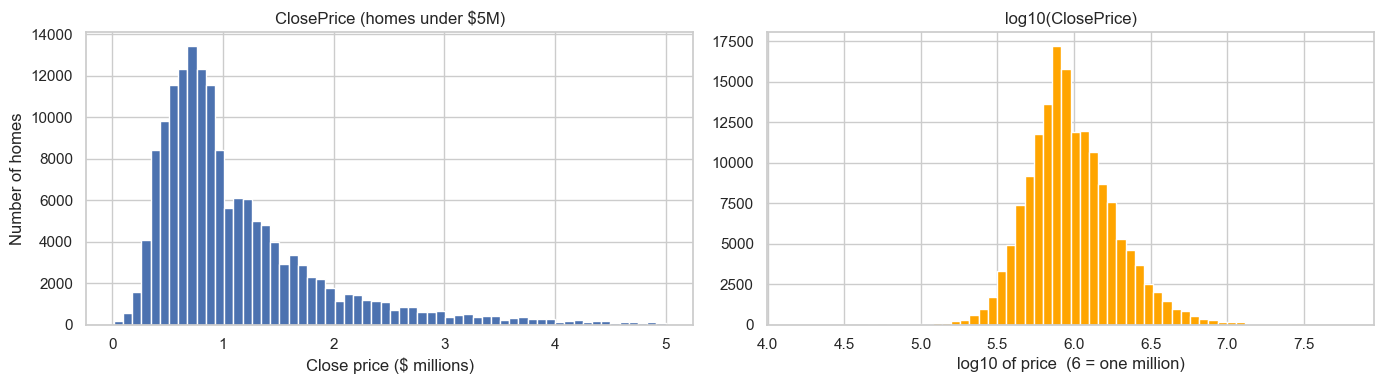

Skewness of price:      8.63
Skewness of log(price): 0.5


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: regular price (only up to $5M so we can see the shape)
axes[0].hist(clean["ClosePrice"][clean["ClosePrice"] < 5_000_000] / 1_000_000, bins=60)
axes[0].set_title("ClosePrice (homes under $5M)")
axes[0].set_xlabel("Close price ($ millions)")
axes[0].set_ylabel("Number of homes")

# Right: log of price
axes[1].hist(np.log10(clean["ClosePrice"]), bins=60, color="orange")
axes[1].set_title("log10(ClosePrice)")
axes[1].set_xlabel("log10 of price  (6 = one million)")

plt.tight_layout()
plt.show()

print("Skewness of price:     ", round(clean["ClosePrice"].skew(), 2))
print("Skewness of log(price):", round(np.log(clean["ClosePrice"]).skew(), 2))

**What I notice:** price is **right-skewed**. Most homes sell between about $500K and $1.5M, with a long tail of expensive homes. After taking the **log**, the distribution looks much more like a bell curve. That could help a linear regression model later.

## 7. Distribution of LivingArea and LotSize

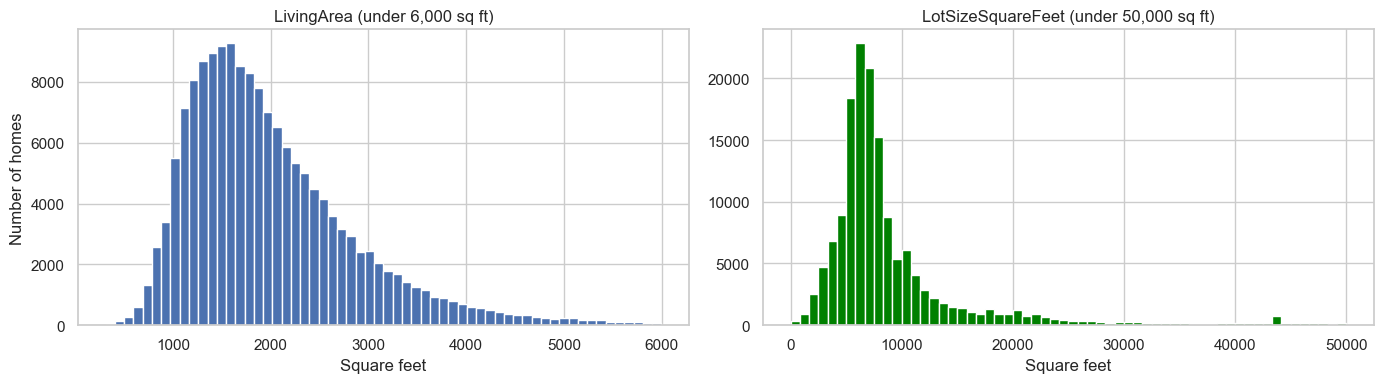

Median living area: 1816.0 sq ft
Median lot size:    7279.0 sq ft


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(clean["LivingArea"][clean["LivingArea"] < 6000], bins=60)
axes[0].set_title("LivingArea (under 6,000 sq ft)")
axes[0].set_xlabel("Square feet")
axes[0].set_ylabel("Number of homes")

lot = clean["LotSizeSquareFeet"]
lot = lot[(lot > 0) & (lot < 50000)]
axes[1].hist(lot, bins=60, color="green")
axes[1].set_title("LotSizeSquareFeet (under 50,000 sq ft)")
axes[1].set_xlabel("Square feet")

plt.tight_layout()
plt.show()

print("Median living area:", clean["LivingArea"].median(), "sq ft")
print("Median lot size:   ", clean["LotSizeSquareFeet"].median(), "sq ft")

**What I notice:** the typical home is about **1,800 sq ft** on a lot of about **7,300 sq ft**. Both are right-skewed. Lot size has some huge values (ranches / land), so it is much more spread out than living area.

## 8. Bedrooms and Bathrooms

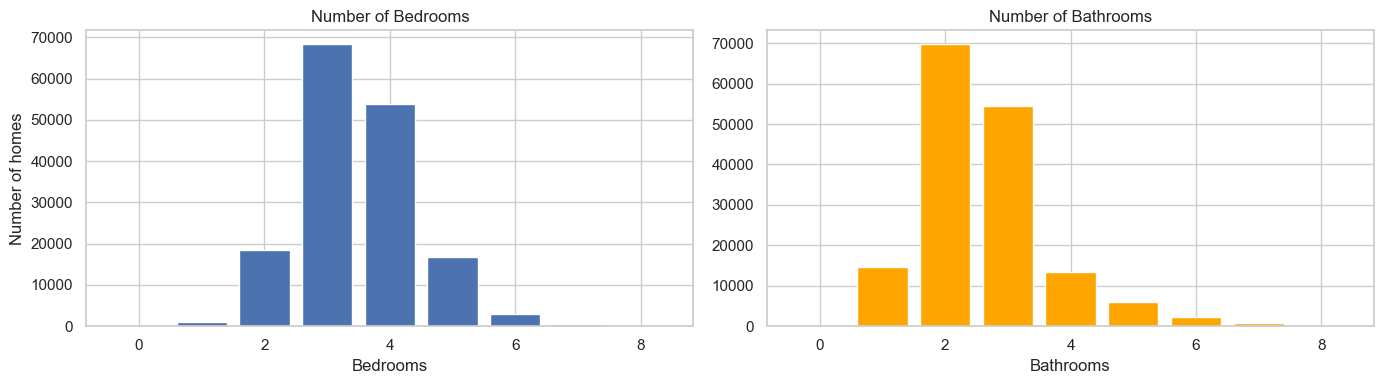

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

bed_counts = clean["BedroomsTotal"].value_counts().sort_index()
bed_counts = bed_counts[bed_counts.index <= 8]
axes[0].bar(bed_counts.index, bed_counts.values)
axes[0].set_title("Number of Bedrooms")
axes[0].set_xlabel("Bedrooms")
axes[0].set_ylabel("Number of homes")

bath_counts = clean["BathroomsTotalInteger"].value_counts().sort_index()
bath_counts = bath_counts[bath_counts.index <= 8]
axes[1].bar(bath_counts.index, bath_counts.values, color="orange")
axes[1].set_title("Number of Bathrooms")
axes[1].set_xlabel("Bathrooms")

plt.tight_layout()
plt.show()

**What I notice:** most homes have **3 or 4 bedrooms** and **2 or 3 bathrooms**.

## 9. How do the features relate to price?
### Living area vs price
I use a random sample of 5,000 homes so the scatter plot isn't too crowded.

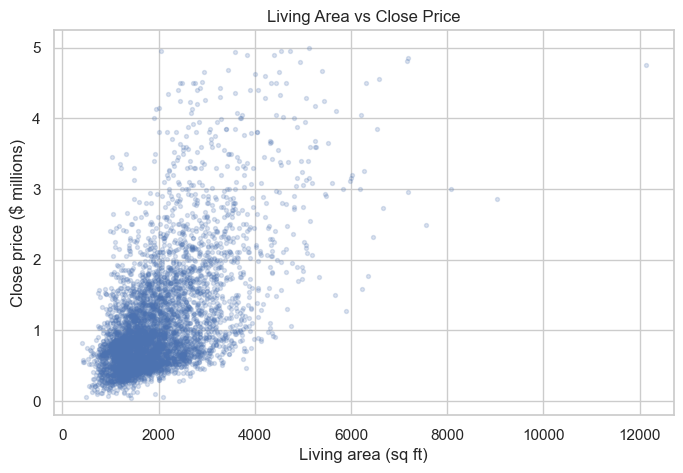

In [40]:
sample = clean.sample(5000, random_state=42)
sample = sample[sample["ClosePrice"] < 5_000_000]

plt.figure(figsize=(8, 5))
plt.scatter(sample["LivingArea"], sample["ClosePrice"] / 1_000_000, alpha=0.2, s=8)
plt.title("Living Area vs Close Price")
plt.xlabel("Living area (sq ft)")
plt.ylabel("Close price ($ millions)")
plt.show()

Bigger homes generally sell for more, but there is a lot of spread. A 2,000 sq ft home can sell for $400K or for $2M+, probably depending on **location**.

### Median price by bedrooms and bathrooms

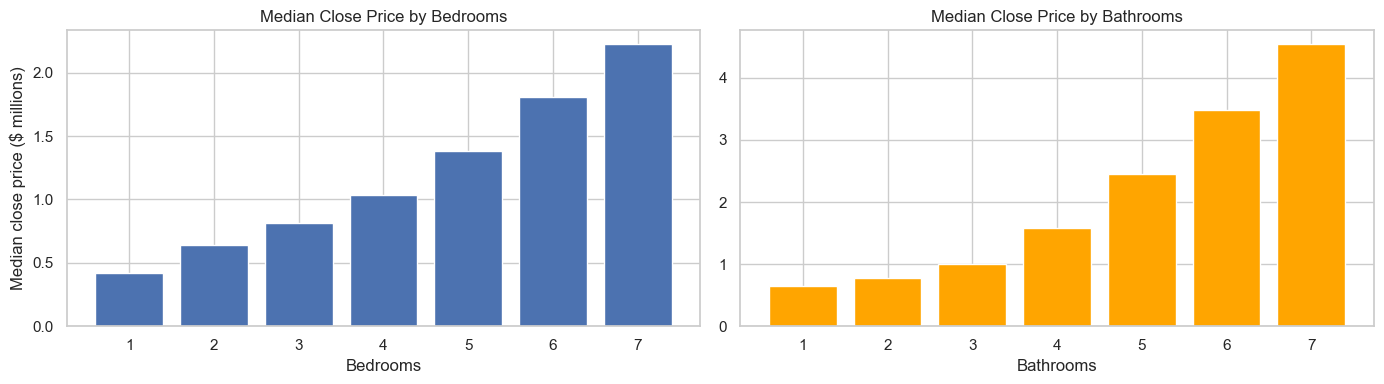

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

by_bed = clean[clean["BedroomsTotal"].between(1, 7)].groupby("BedroomsTotal")["ClosePrice"].median()
axes[0].bar(by_bed.index, by_bed.values / 1_000_000)
axes[0].set_title("Median Close Price by Bedrooms")
axes[0].set_xlabel("Bedrooms")
axes[0].set_ylabel("Median close price ($ millions)")

by_bath = clean[clean["BathroomsTotalInteger"].between(1, 7)].groupby("BathroomsTotalInteger")["ClosePrice"].median()
axes[1].bar(by_bath.index, by_bath.values / 1_000_000, color="orange")
axes[1].set_title("Median Close Price by Bathrooms")
axes[1].set_xlabel("Bathrooms")

plt.tight_layout()
plt.show()

Price goes up with both, but it goes up faster with **bathrooms** than with bedrooms.

### Correlation heatmap

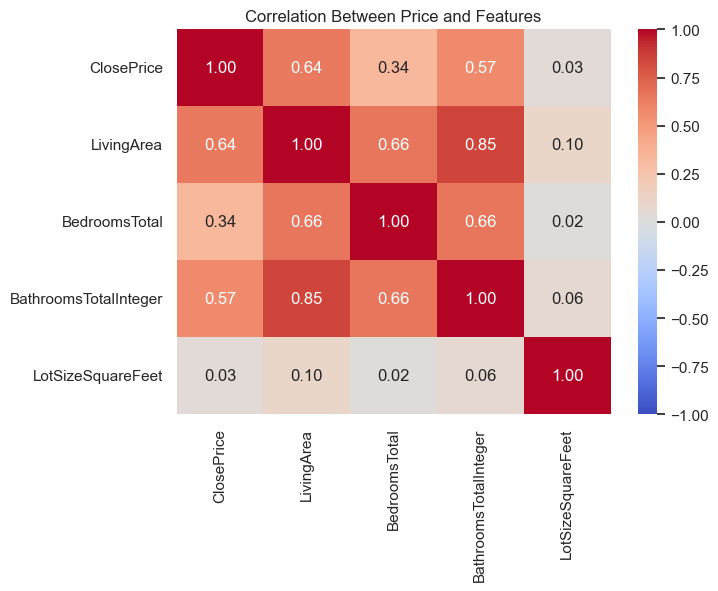

In [42]:
corr = clean[cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Price and Features")
plt.show()

**What I notice:**
- `LivingArea` has the strongest correlation with price (~0.64), then bathrooms (~0.57).
- Bedrooms are weaker (~0.34), and lot size is almost 0.
- Living area, bedrooms and bathrooms are also correlated **with each other**, which makes sense since bigger homes have more rooms.

*(Side note: before removing the typo rows, the correlation of living area with price was only about 0.12. A few bad rows can really mess up a correlation.)*

## 10. Median price by county

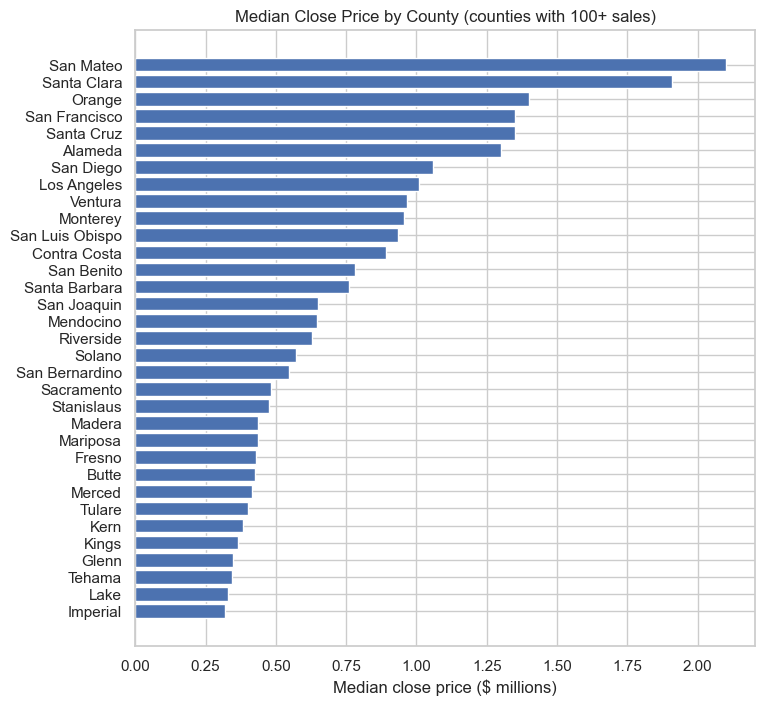

In [43]:
county = clean.groupby("CountyOrParish")["ClosePrice"].agg(["count", "median"])
county = county[county["count"] >= 100].sort_values("median")

plt.figure(figsize=(8, 8))
plt.barh(county.index, county["median"] / 1_000_000)
plt.title("Median Close Price by County (counties with 100+ sales)")
plt.xlabel("Median close price ($ millions)")
plt.show()

Location makes a huge difference. San Mateo's median is over **$2M**, while some inland counties are around **$300–400K**. County (or city) will probably be an important feature.

## 11. Price over time

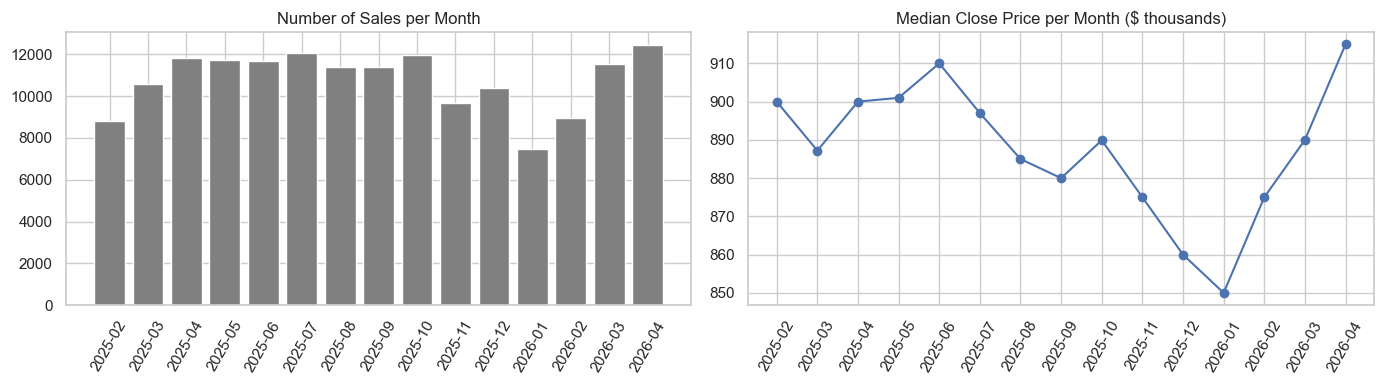

In [44]:
clean["CloseDate"] = pd.to_datetime(clean["CloseDate"])
clean["Month"] = clean["CloseDate"].dt.to_period("M").astype(str)

monthly = clean.groupby("Month")["ClosePrice"].agg(["count", "median"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(monthly.index, monthly["count"], color="gray")
axes[0].set_title("Number of Sales per Month")
axes[0].tick_params(axis="x", rotation=60)

axes[1].plot(monthly.index, monthly["median"] / 1000, marker="o")
axes[1].set_title("Median Close Price per Month ($ thousands)")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

Sales drop in the winter (January is the lowest) and pick back up in spring. The median price dipped to about **$850K** in January 2026 and went back up to about **$910K** by April 2026. This matters for Week 3, because we test on the most recent month.

---
## Summary of findings

1. **Data:** 15 months, 324,496 sales → **162,454** single-family homes after filtering and removing duplicates.
2. **ClosePrice** is right-skewed (median $890K). Taking the **log** makes it look normal.
3. There are some clear **data errors**: prices about 1,000× too high, $0 sales, 0 sq ft homes, and 45-bedroom homes. These need to be cleaned in Week 3.
4. **Missing values** are rare for the main features (lot size is the highest at ~1.7%).
5. **LivingArea** is the strongest predictor of price, then bathrooms. Lot size alone doesn't say much.
6. **Location** (county/city) has a big effect on price.
7. Prices change a little from **month to month**, which matters for the time-based train/test split.

**Next (Week 3):** handle missing values and errors, encode categorical columns, and build the train/test split → 02_preprocessing.ipynb.